In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = sns.load_dataset("titanic")

In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
print("Number of rows and columns:",df.shape)

Number of rows and columns: (891, 15)


In [5]:
print("column names:",df.columns.tolist())

column names: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [7]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
print("Missing values in each column:",df.isnull().sum())

Missing values in each column: survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [9]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing value percentage:")
print(missing_percentage)

Missing value percentage:
survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64


In [10]:
print("Number of duplicate rows:",df.duplicated().sum())

Number of duplicate rows: 107


In [11]:
df=df.drop_duplicates()
print("duplicates removed.")
print("new dataset shape:",df.shape)

duplicates removed.
new dataset shape: (784, 15)


In [12]:

df["age"] = df["age"].fillna(df["age"].median())

print("Missing Age values after cleaning:",
      df["age"].isnull().sum())

Missing Age values after cleaning: 0


In [13]:

df["embarked"] = df["embarked"].fillna(
    df["embarked"].mode()[0]
)

print("Missing Embarked values after cleaning:",
      df["embarked"].isnull().sum())

Missing Embarked values after cleaning: 0


In [14]:
df=df.drop(columns=["deck"])
print("Deck column removed.")

Deck column removed.


In [15]:
df=df.drop(columns=["embark_town"])
print("embark_town column removed.")

embark_town column removed.


In [16]:
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
survived      0
pclass        0
sex           0
age           0
sibsp         0
parch         0
fare          0
embarked      0
class         0
who           0
adult_male    0
alive         0
alone         0
dtype: int64


In [17]:
print(df["sex"].value_counts())

sex
male      491
female    293
Name: count, dtype: int64


In [18]:
print(df["embarked"].value_counts())

embarked
S    570
C    155
Q     59
Name: count, dtype: int64


In [19]:
print("Sex:", df["sex"].unique())

print("Embarked:", df["embarked"].unique())

Sex: ['male' 'female']
Embarked: ['S' 'C' 'Q']


In [20]:
selected_columns = [
    "pclass",
    "sex",
    "age",
    "sibsp",
    "parch",
    "fare",
    "embarked",
    "survived"
]

df = df[selected_columns]

print("Selected features:")
print(df.columns.tolist())

Selected features:
['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'survived']


In [21]:
df = pd.get_dummies(
    df,
    columns=["sex", "embarked"],
    drop_first=True
)

df.head()

,pclass,age,sibsp,parch,fare,survived,sex_male,embarked_Q,embarked_S
0,3,22.0,1,0,7.2500,0,True,False,True
1,1,38.0,1,0,71.2833,1,False,False,False
2,3,26.0,0,0,7.9250,1,False,False,True
3,1,35.0,1,0,53.1000,1,False,False,True
4,3,35.0,0,0,8.0500,0,True,False,True


In [22]:
print(df.dtypes)

pclass          int64
age           float64
sibsp           int64
parch           int64
fare          float64
survived        int64
sex_male         bool
embarked_Q       bool
embarked_S       bool
dtype: object


In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

numerical_columns = ["age", "fare"]

df[numerical_columns] = scaler.fit_transform(
    df[numerical_columns]
)

print("Numerical features standardized.")

Numerical features standardized.


In [24]:
df.head()

,pclass,age,sibsp,parch,fare,survived,sex_male,embarked_Q,embarked_S
0,3,-0.557360,1,0,-0.526825,0,True,False,True
1,1,0.608298,1,0,0.701587,1,False,False,False
2,3,-0.265945,0,0,-0.513876,1,False,False,True
3,1,0.389737,1,0,0.352760,1,False,False,True
4,3,0.389737,0,0,-0.511478,0,True,False,True


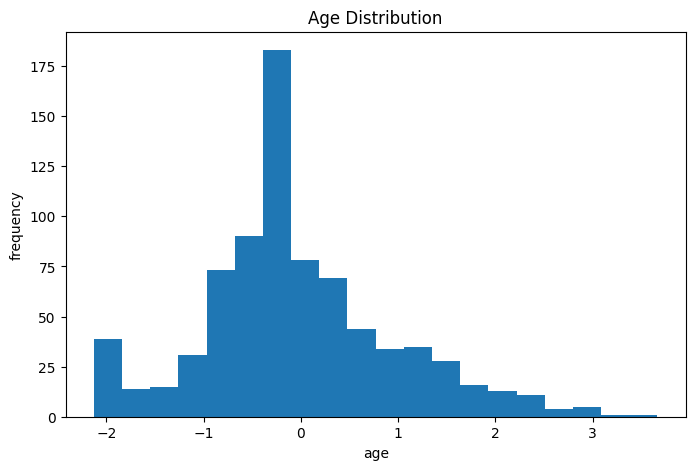

In [25]:
plt.figure(figsize=(8, 5))

plt.hist(df["age"], bins=20)

plt.title("Age Distribution")
plt.xlabel("age")
plt.ylabel("frequency")

plt.show()

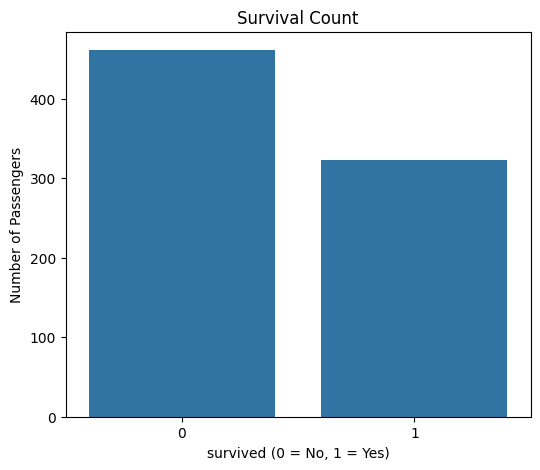

In [26]:
plt.figure(figsize=(6, 5))

sns.countplot(x="survived", data=df)

plt.title("Survival Count")
plt.xlabel("survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

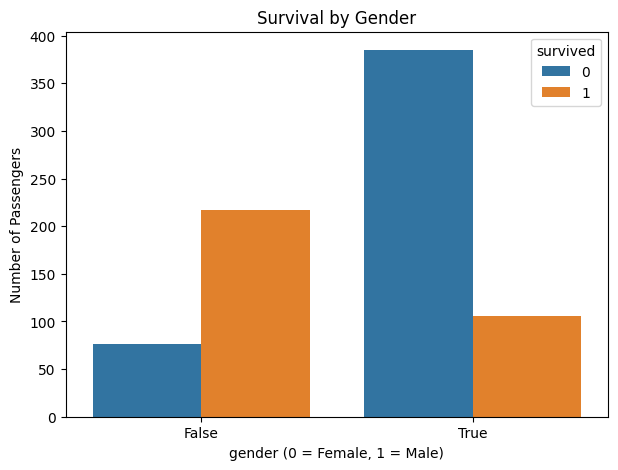

In [27]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x="sex_male",
    hue="survived",
    data=df
)

plt.title("Survival by Gender")
plt.xlabel("gender (0 = Female, 1 = Male)")
plt.ylabel("Number of Passengers")

plt.show()

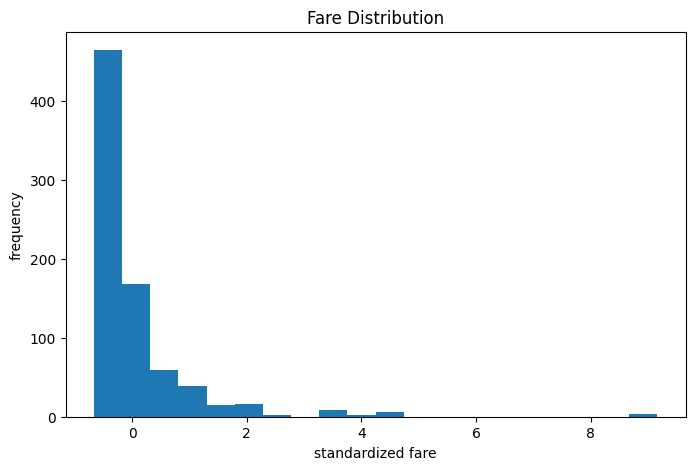

In [28]:
plt.figure(figsize=(8, 5))

plt.hist(df["fare"], bins=20)

plt.title("Fare Distribution")
plt.xlabel("standardized fare")
plt.ylabel("frequency")

plt.show()

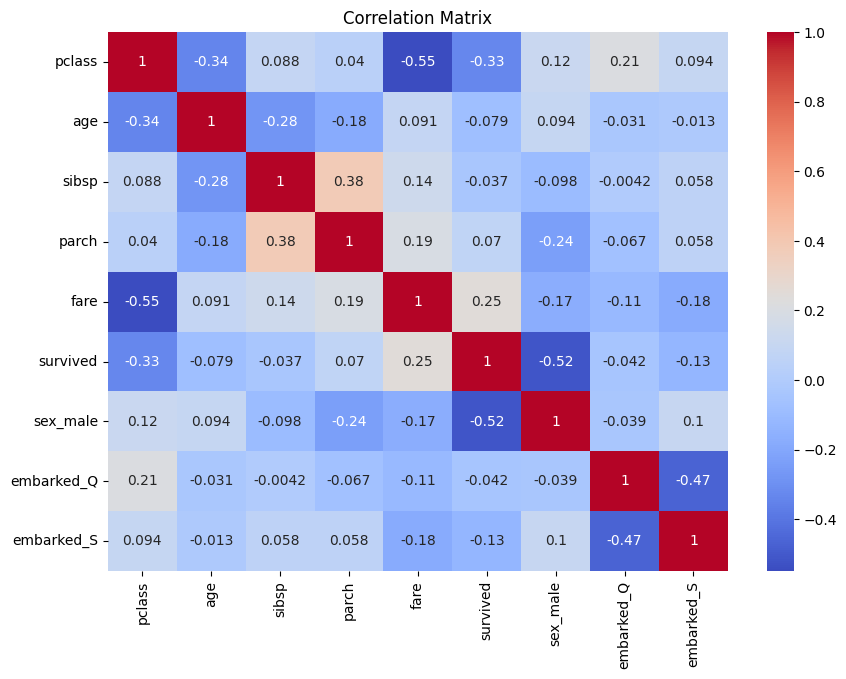

In [29]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

In [30]:
print("Final dataset shape:", df.shape)

print("\nFinal missing values:")
print(df.isnull().sum())

print("\nFinal data types:")
print(df.dtypes)

Final dataset shape: (784, 9)

Final missing values:
pclass        0
age           0
sibsp         0
parch         0
fare          0
survived      0
sex_male      0
embarked_Q    0
embarked_S    0
dtype: int64

Final data types:
pclass          int64
age           float64
sibsp           int64
parch           int64
fare          float64
survived        int64
sex_male         bool
embarked_Q       bool
embarked_S       bool
dtype: object


In [31]:
df.to_csv("cleaned_titanic.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [32]:
from google.colab import files

files.download("cleaned_titanic.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Week 2: Supervised Machine Learning Models

## Objective
The objective of this task is to implement supervised machine learning algorithms using Scikit-learn.

The Titanic dataset from Week 1 will be reused to build classification and regression models. The models will be trained, used for prediction, evaluated using performance metrics, and compared to identify their strengths and weaknesses.

### Algorithms
1. Linear Regression
2. Logistic Regression
3. Decision Tree
4. Random Forest
5. K-Nearest Neighbors (KNN)

In [33]:
# Step 1: Check the dataset from Week 1

print("Dataset shape:", df.shape)
print("\nDataset columns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (784, 9)

Dataset columns:
['pclass', 'age', 'sibsp', 'parch', 'fare', 'survived', 'sex_male', 'embarked_Q', 'embarked_S']


,pclass,age,sibsp,parch,fare,survived,sex_male,embarked_Q,embarked_S
0,3,-0.557360,1,0,-0.526825,0,True,False,True
1,1,0.608298,1,0,0.701587,1,False,False,False
2,3,-0.265945,0,0,-0.513876,1,False,False,True
3,1,0.389737,1,0,0.352760,1,False,False,True
4,3,0.389737,0,0,-0.511478,0,True,False,True


In [34]:
# Step 2: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [35]:
# Step 3: Prepare classification data

classification_df = df.copy()

# Remove rows where the target is missing
classification_df = classification_df.dropna(subset=["survived"])

# Target variable
y = classification_df["survived"].astype(int)

# Remove the target and columns that directly reveal survival
columns_to_drop = [
    "survived",
    "alive",
    "name",
    "ticket",
    "cabin",
    "boat",
    "body",
    "home.dest"
]

X = classification_df.drop(
    columns=[
        col for col in columns_to_drop
        if col in classification_df.columns
    ]
)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (784, 8)
Target shape: (784,)

Target distribution:
survived
0    461
1    323
Name: count, dtype: int64


In [36]:
# Step 3: Prepare classification data

classification_df = df.copy()

# Remove rows where the target is missing
classification_df = classification_df.dropna(subset=["survived"])

# Target variable
y = classification_df["survived"].astype(int)

# Remove the target and columns that directly reveal survival
columns_to_drop = [
    "survived",
    "alive",
    "name",
    "ticket",
    "cabin",
    "boat",
    "body",
    "home.dest"
]

X = classification_df.drop(
    columns=[
        col for col in columns_to_drop
        if col in classification_df.columns
    ]
)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (784, 8)
Target shape: (784,)

Target distribution:
survived
0    461
1    323
Name: count, dtype: int64


In [37]:
# Step 4: Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Preprocessing for numerical columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Numerical features: ['pclass', 'age', 'sibsp', 'parch', 'fare', 'sex_male', 'embarked_Q', 'embarked_S']
Categorical features: []
Preprocessing pipeline created successfully!


In [38]:
# Step 5: Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 627
Testing samples: 157


In [39]:
# Step 6: Build and train Logistic Regression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)

print("Logistic Regression training completed!")
print("First 10 predictions:", y_pred_logistic[:10])

Logistic Regression training completed!
First 10 predictions: [1 1 0 0 1 1 0 0 0 0]


In [40]:
# Step 7: Build and train Decision Tree

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

y_pred_tree = decision_tree_model.predict(X_test)

print("Decision Tree training completed!")
print("First 10 predictions:", y_pred_tree[:10])

Decision Tree training completed!
First 10 predictions: [1 0 0 0 1 1 0 0 0 1]


In [41]:
# Step 8: Build and train Random Forest

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42
    ))
])

random_forest_model.fit(X_train, y_train)

y_pred_forest = random_forest_model.predict(X_test)

print("Random Forest training completed!")
print("First 10 predictions:", y_pred_forest[:10])

Random Forest training completed!
First 10 predictions: [1 0 0 0 1 1 0 0 0 1]


In [42]:
# Step 9: Build and train KNN

knn_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

print("KNN training completed!")
print("First 10 predictions:", y_pred_knn[:10])

KNN training completed!
First 10 predictions: [1 0 0 0 1 1 0 1 0 0]


In [43]:
# Step 10: Evaluate classification models

classification_models = {
    "Logistic Regression": (logistic_model, y_pred_logistic),
    "Decision Tree": (decision_tree_model, y_pred_tree),
    "Random Forest": (random_forest_model, y_pred_forest),
    "KNN": (knn_model, y_pred_knn)
}

classification_results = []

for name, (model, predictions) in classification_models.items():
    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

classification_results = pd.DataFrame(classification_results)

display(
    classification_results
    .sort_values("F1 Score", ascending=False)
    .round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.8344,0.8421,0.7385,0.7869
0,Logistic Regression,0.8153,0.7647,0.8000,0.7820
3,KNN,0.8025,0.8148,0.6769,0.7395
1,Decision Tree,0.8089,0.8571,0.6462,0.7368


In [44]:
# Step 11: Detailed classification report for Random Forest

print(
    classification_report(
        y_test,
        y_pred_forest,
        target_names=["Did Not Survive", "Survived"],
        zero_division=0
    )
)

                 precision    recall  f1-score   support

Did Not Survive       0.83      0.90      0.86        92
       Survived       0.84      0.74      0.79        65

       accuracy                           0.83       157
      macro avg       0.84      0.82      0.83       157
   weighted avg       0.84      0.83      0.83       157



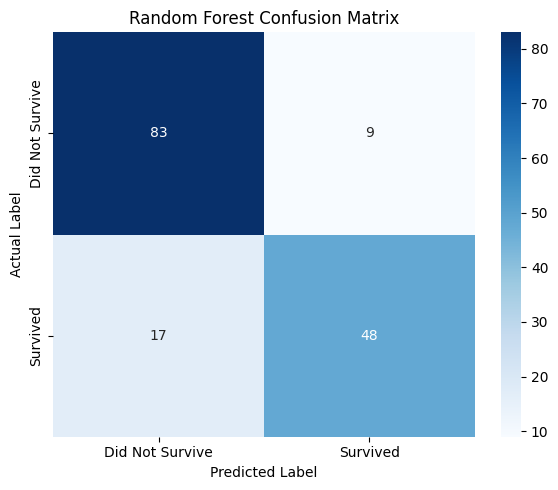

In [45]:
# Step 12: Confusion matrix for Random Forest

cm = confusion_matrix(y_test, y_pred_forest)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Did Not Survive", "Survived"],
    yticklabels=["Did Not Survive", "Survived"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [46]:
# Step 13: Prepare regression data

regression_df = df.copy()

regression_df = regression_df.dropna(subset=["fare"])

# Target variable
y_reg = regression_df["fare"]

# Remove fare and survival-related columns from the features
regression_columns_to_drop = [
    "fare",
    "survived",
    "alive",
    "name",
    "ticket",
    "cabin",
    "boat",
    "body",
    "home.dest"
]

X_reg = regression_df.drop(
    columns=[
        col for col in regression_columns_to_drop
        if col in regression_df.columns
    ]
)

print("Regression feature shape:", X_reg.shape)
print("Regression target shape:", y_reg.shape)

display(X_reg.head())

Regression feature shape: (784, 7)
Regression target shape: (784,)


,pclass,age,sibsp,parch,sex_male,embarked_Q,embarked_S
0,3,-0.557360,1,0,True,False,True
1,1,0.608298,1,0,False,False,False
2,3,-0.265945,0,0,False,False,True
3,1,0.389737,1,0,False,False,True
4,3,0.389737,0,0,True,False,True


In [47]:
# Step 14: Train-test split for regression

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train_reg))
print("Testing samples:", len(X_test_reg))

Training samples: 627
Testing samples: 157


In [48]:
# Step 15: Build and train Linear Regression

linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor.__class__(
        transformers=[
            (
                "num",
                numeric_transformer,
                X_reg.select_dtypes(
                    include=["number", "bool"]
                ).columns.tolist()
            ),
            (
                "cat",
                categorical_transformer,
                X_reg.select_dtypes(
                    include=["object", "category", "string"]
                ).columns.tolist()
            )
        ]
    )),
    ("model", LinearRegression())
])

linear_model.fit(X_train_reg, y_train_reg)

y_pred_linear = linear_model.predict(X_test_reg)

print("Linear Regression training completed!")
print("First 10 predicted fares:", np.round(y_pred_linear[:10], 2))

Linear Regression training completed!
First 10 predicted fares: [-0.57 -0.77 -0.8  -0.75  0.37 -0.71 -0.59 -0.65  0.63 -0.02]


In [49]:
# Step 16: Build and train Random Forest Regressor

regression_preprocessor = linear_model.named_steps["preprocessor"]

rf_regression_model = Pipeline(steps=[
    ("preprocessor", regression_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42
    ))
])

rf_regression_model.fit(X_train_reg, y_train_reg)

y_pred_rf_reg = rf_regression_model.predict(X_test_reg)

print("Random Forest Regression training completed!")
print("First 10 predicted fares:", np.round(y_pred_rf_reg[:10], 2))

Random Forest Regression training completed!
First 10 predicted fares: [-0.51 -0.52 -0.52 -0.49  0.11 -0.5  -0.51 -0.51  0.49 -0.18]


In [50]:
# Step 17: Compare regression models

regression_models = {
    "Linear Regression": y_pred_linear,
    "Random Forest Regressor": y_pred_rf_reg
}

regression_results = []

for name, predictions in regression_models.items():
    regression_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_reg, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, predictions)),
        "R2 Score": r2_score(y_test_reg, predictions)
    })

regression_results = pd.DataFrame(regression_results)

display(regression_results.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.4587,0.9077,0.3678
1,Random Forest Regressor,0.3287,0.9360,0.3278


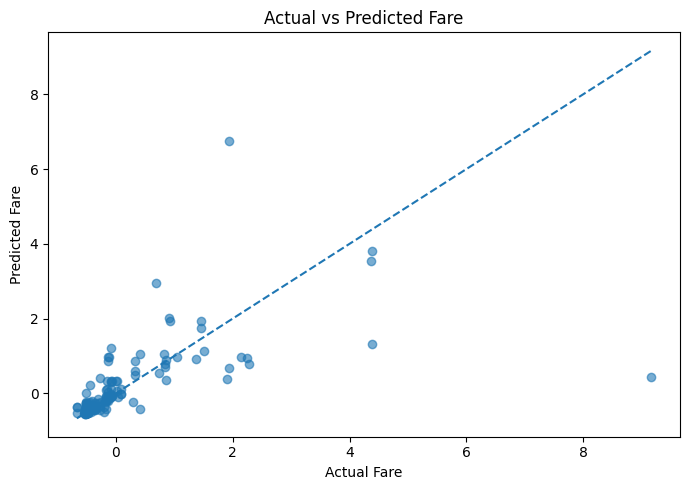

In [51]:
# Step 18: Visualize Random Forest regression predictions

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test_reg,
    y_pred_rf_reg,
    alpha=0.6
)

# Reference line for perfect predictions
minimum = min(y_test_reg.min(), y_pred_rf_reg.min())
maximum = max(y_test_reg.max(), y_pred_rf_reg.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Fare")
plt.tight_layout()
plt.show()

In [52]:
# Step 19: Display final results

print("========== CLASSIFICATION RESULTS ==========")
display(
    classification_results
    .sort_values("F1 Score", ascending=False)
    .round(4)
)

print("\n========== REGRESSION RESULTS ==========")
display(regression_results.round(4))

========== CLASSIFICATION RESULTS ==========


,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.8344,0.8421,0.7385,0.7869
0,Logistic Regression,0.8153,0.7647,0.8000,0.7820
3,KNN,0.8025,0.8148,0.6769,0.7395
1,Decision Tree,0.8089,0.8571,0.6462,0.7368



========== REGRESSION RESULTS ==========


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.4587,0.9077,0.3678
1,Random Forest Regressor,0.3287,0.9360,0.3278
